# Model Training and Selection - Dzifa, Avi, Erin, Aarabhi

Trains the final clause classifier (41 CUAD categories, multi-label), evaluates it on the validation set, scores the test set once, and writes the test predictions used by the risk classifier.

**Final model:** `legal-bert-focal-optuna`: Legal-BERT (`nlpaueb/legal-bert-base-uncased`) + focal loss (γ = 2) + class weights (power 0.5, cap 10), learning rate 5.8e-5, 20 epochs (best epoch kept), warmup 0.028, weight decay 0.098. Validation macro F1 is about 0.66 chunk-level and 0.79 contract-level (two seeds).

**Pipeline**
1. Load the chunks and the 61-contract validation split; tokenize
2. Train the final model, validate every epoch, keep the best epoch (skipped if its results already exist)
3. Validation results: chunk- and contract-level scores, per-category F1
4. Score the test set **once** (`FINAL_RUN`) and write `test_predictions.parquet`

**Scores:** *chunk-level* = the right clause in each 512-token chunk; *contract-level* = the clause found anywhere in the contract. All choices were made on the validation set.

**How to run:** on Colab with a GPU. `RUN_MODE = "auto"` runs **full** on a GPU and **smoke** (small subset, meaningless scores) on CPU. Results are saved to Google Drive. Training the final model from scratch takes about 18 minutes on an A100.

**How the final model was chosen:** the experiments (class-weighting grid, focal and asymmetric loss, threshold check, Optuna tuning and seed check, data variants, ModernBERT) are in `notebooks/experimentation/Transformer/`.

## 0. Google Colab setup
On Colab: clones the repo, installs `requirements.txt`, mounts Google Drive (results are saved there). Does nothing elsewhere.

In [1]:
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/Break-Through-Tech/Accenture-1H-contract-review-challenge.git"
REPO_BRANCH = "main"
SAVE_TO_DRIVE = True                          # Colab only: keep results/checkpoints on Google Drive

if IN_COLAB:
    repo_dir = "/content/Accenture-1H-contract-review-challenge"
    if not os.path.exists(repo_dir):
        cloned = subprocess.run(["git", "clone", "--depth", "1", "-b", REPO_BRANCH, REPO_URL, repo_dir]).returncode == 0
        if not cloned:   # branch not on GitHub (yet): main has the same data files
            print(f"Branch {REPO_BRANCH} not found, cloning main instead.")
            subprocess.run(["git", "clone", "--depth", "1", REPO_URL, repo_dir], check=True)
    os.chdir(f"{repo_dir}/notebooks/pipeline")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "../../requirements.txt"], check=True)
    if SAVE_TO_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
print("In Colab:", IN_COLAB, "| working dir:", os.getcwd())

Mounted at /content/drive
In Colab: True | working dir: /content/Accenture-1H-contract-review-challenge/notebooks/pipeline


## 1. Setup

In [2]:
import gc, json, re, shutil, time, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import transformers
from datasets import Dataset, DatasetDict, Features, Sequence, Value, load_from_disk, disable_progress_bars
from sklearn.metrics import average_precision_score, precision_recall_fscore_support
from transformers import (AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding,
                          Trainer, TrainingArguments, set_seed)
from sklearn.metrics import f1_score, precision_recall_curve

transformers.logging.set_verbosity_error()   # hide the expected "newly initialized classifier" warning
disable_progress_bars()                       # keep tokenization output short
print("torch", torch.__version__, "| transformers", transformers.__version__)

torch 2.14.1+cu130 | transformers 4.57.6


All settings. `RUNS` holds only the final model; `SKIP_FINISHED` reuses its saved results instead of retraining.

In [3]:
RUN_MODE = "auto"      # "auto" (full if a GPU is available, else smoke), "full", or "smoke"
SEED = 42
DATA_DIR = "../../data/processed"

MODELS = {   # short tag -> Hugging Face model name
    "roberta": "roberta-base",                         # only used by the tokenizer checks in section 4
    "legal-bert": "nlpaueb/legal-bert-base-uncased",
}

# The final model. Its loss was chosen in the loss experiments and its training settings with Optuna (8 trials),
# confirmed with a second seed: see notebooks/experimentation/Transformer/.
#   power, cap  : class weights. pos_weight = clip((negatives / positives) ** power, 1, cap)
#   loss, gamma : focal loss; easy examples count less (gamma = 0 is plain BCE)
#   learning_rate, num_epochs, warmup_ratio, weight_decay : training settings (full mode; smoke mode uses SMOKE below)
RUNS = {
    "legal-bert-focal-optuna": dict(model="legal-bert", loss="focal", gamma=2, power=0.5, cap=10,
                                    learning_rate=5.833508124642314e-05, num_epochs=20,
                                    warmup_ratio=0.027812682368409187, weight_decay=0.09767852842594692),
}
assert all(r["model"] in MODELS for r in RUNS.values())

RUNS_TO_RUN = ["legal-bert-focal-optuna"]
SKIP_FINISHED = True   # don't retrain a model whose summary.json already exists (its saved results are used instead)

MAX_LENGTH = 512       # both models' input limit
OVERLAP = 128          # chunk overlap used in 02_data_tokenization_and_chunking.ipynb
THRESHOLD = 0.5        # decision threshold (a global-threshold check in the experiments found 0.5 best for this model)
SELECT_METRIC = "macro_ap"   # validation metric used to choose the best epoch (see section 5)
WINNER_METRIC = "macro_f1"   # validation metric reported for the run (the project goal is macro F1)
SCORE_TEST_PER_RUN = False   # False: the test set is NOT scored during training; it is scored once, for FINAL_RUN (section 8)
FINAL_RUN = None             # set to "legal-bert-focal-optuna" to score the test set once (section 8)

# Defaults; a run's own settings in RUNS override these in full mode. The results folder is named after
# the default epochs (results/training/15ep/); each run's actual settings are saved in its summary.json.
FULL = dict(num_epochs=15, learning_rate=2e-5, effective_batch_size=16, max_length=MAX_LENGTH,
            warmup_ratio=0.1, weight_decay=0.01, subset=None)
SMOKE = dict(num_epochs=3, learning_rate=5e-5, effective_batch_size=16, max_length=128,
             warmup_ratio=0.1, weight_decay=0.01, subset={"train": 384, "validation": 128, "test": 128})

if not os.path.exists(DATA_DIR):
    raise FileNotFoundError(f"{DATA_DIR} not found. Run this notebook from the notebooks/pipeline/ folder.")
set_seed(SEED)

## 2. GPU training environment
Checks the device and turns on mixed precision on GPU (bf16 if supported, else fp16). The per-step batch size depends on GPU memory; gradient accumulation keeps the **effective batch size at 16**.

In [4]:
HAS_GPU = torch.cuda.is_available()
MODE = ("full" if HAS_GPU else "smoke") if RUN_MODE == "auto" else RUN_MODE
CFG = dict(FULL if MODE == "full" else SMOKE)

print("Python:", platform.python_version(), "| CPU cores:", os.cpu_count())
if HAS_GPU:
    props = torch.cuda.get_device_properties(0)
    vram_gb = props.total_memory / 1e9
    print(f"GPU: {props.name} | {vram_gb:.1f} GB | CUDA {torch.version.cuda}")
    USE_BF16 = torch.cuda.is_bf16_supported()
    USE_FP16 = not USE_BF16
    per_device = 16 if vram_gb >= 40 else 8 if vram_gb >= 14 else 4
else:
    print("GPU: none found. Training runs on CPU.")
    if IN_COLAB:
        print("  -> On Colab: Runtime > Change runtime type > T4 GPU (or better), then run all again.")
    USE_BF16 = USE_FP16 = False
    per_device = 8
if MODE == "full" and not HAS_GPU:
    print("WARNING: full mode on CPU will take many hours per epoch.")

# Make sure the device can actually run a computation
device = torch.device("cuda" if HAS_GPU else "cpu")
a = torch.randn(1024, 1024, device=device)
assert torch.isfinite(a @ a).all()

CFG["per_device_batch_size"] = min(per_device, CFG["effective_batch_size"])
CFG["grad_accum_steps"] = CFG["effective_batch_size"] // CFG["per_device_batch_size"]
print(f"Device check passed on {device}. Mode: {MODE} | precision: "
      f"{'bf16' if USE_BF16 else 'fp16' if USE_FP16 else 'fp32'} | batch {CFG['per_device_batch_size']} "
      f"x {CFG['grad_accum_steps']} accumulation = {CFG['effective_batch_size']}")

Python: 3.13.16 | CPU cores: 12
GPU: NVIDIA A100-SXM4-40GB | 42.4 GB | CUDA 13.0
Device check passed on cuda. Mode: full | precision: bf16 | batch 16 x 1 accumulation = 16


In [5]:
# results/ is committed, models/ is not. Each run gets its own folder (e.g. 15ep). Smoke runs stay under models/.
RUN_NAME = f"{CFG['num_epochs']}ep"
OUTPUT_ROOT = "/content/drive/MyDrive/Accenture-1H-contract-review-challenge" if (IN_COLAB and SAVE_TO_DRIVE) else "../.."
RESULTS_DIR = f"{OUTPUT_ROOT}/results/training/{RUN_NAME}" if MODE == "full" else f"{OUTPUT_ROOT}/models/training_smoke/results"
MODELS_DIR = f"{OUTPUT_ROOT}/models/training/{RUN_NAME}" if MODE == "full" else f"{OUTPUT_ROOT}/models/training_smoke"
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)
print("Results:", RESULTS_DIR, "\nCheckpoints:", MODELS_DIR)

Results: /content/drive/MyDrive/Accenture-1H-contract-review-challenge/results/training/15ep 
Checkpoints: /content/drive/MyDrive/Accenture-1H-contract-review-challenge/models/training/15ep


In [6]:
# Bring in finished runs that are committed to the repo (results/), so the comparison in section 7 includes them.
# Checkpoints are not in git: scoring a run on the test set needs the Drive that trained it.
for r in RUNS:
    committed, here = f"../../results/training/{RUN_NAME}/{r}", f"{RESULTS_DIR}/{r}"
    if os.path.exists(committed) and not os.path.exists(here):
        shutil.copytree(committed, here)
print(sorted(os.listdir(RESULTS_DIR)))

['legal-bert', 'legal-bert-asl', 'legal-bert-focal-g2-p0.5-c10', 'legal-bert-focal-optuna', 'legal-bert-focal-optuna-seed43', 'legal-bert-w-p0.5-c10-dlb-k0.5', 'legal-bert-w-p0.5-c10-dlb-k1.0', 'legal-bert-w-p0.5-c10-dorig-k0.5', 'legal-bert-w-p0.5-c10-dorig-k1.0', 'legal-bert-w-p0.5-c20', 'legal-bert-w-p0.5-c5', 'legal-bert-w-p0.5-c7', 'legal-bert-w-p0.75-c10', 'legal-bert-w-p0.75-c20', 'legal-bert-w-p0.75-c7', 'legal-bert-weighted', 'loss_curves.png', 'model_comparison.csv', 'modernbert-w-p0.5-c10-dmb-k1.0', 'modernbert-w-p0.5-c10-dorig-k1.0', 'optuna', 'roberta', 'val_labels.npy']


## 3. Load the chunks and the validation split
Same inputs and 61-contract validation split (`val_titles.json`) as `04_data_preparation.ipynb`. The splits are rebuilt from the text because Legal-BERT needs its own tokenizer; `roberta_dataset/` only has RoBERTa token IDs.

In [7]:
train_df = pd.read_parquet(f"{DATA_DIR}/train_chunks_labeled.parquet")
test_df = pd.read_parquet(f"{DATA_DIR}/test_chunks_labeled.parquet")
with open(f"{DATA_DIR}/categories.json") as f:
    CATEGORIES = json.load(f)
with open(f"{DATA_DIR}/val_titles.json") as f:
    val_titles = set(json.load(f)["val_titles"])
train_titles = set(train_df["title"]) - val_titles

FEATURES = Features({"title": Value("string"), "chunk_id": Value("int64"), "chunk_text": Value("string"),
                     "labels": Sequence(Value("float32"), length=len(CATEGORIES))})

def build_split(df, titles):
    part = df[df["title"].isin(titles)].reset_index(drop=True)
    out = part[["title", "chunk_id", "chunk_text"]].copy()
    out["labels"] = list(part[CATEGORIES].to_numpy(dtype=np.float32))
    return Dataset.from_pandas(out, features=FEATURES, preserve_index=False)

raw = DatasetDict({"train": build_split(train_df, train_titles),
                   "validation": build_split(train_df, val_titles),
                   "test": build_split(test_df, set(test_df["title"]))})

assert len(CATEGORIES) == 41 and len(val_titles) == 61 and len(train_titles) == 347
assert not (val_titles & train_titles) and not (set(train_df["title"]) & set(test_df["title"]))
assert (raw["train"].num_rows, raw["validation"].num_rows, raw["test"].num_rows) == (12112, 2069, 2898)
print({k: v.num_rows for k, v in raw.items()}, "| load checks passed.")

{'train': 12112, 'validation': 2069, 'test': 2898} | load checks passed.


## 4. Tokenizers: RoBERTa and Legal-BERT
- **RoBERTa** (`roberta-base`): cased byte-level BPE. Chunks were cut to 512 RoBERTa tokens.
- **Legal-BERT**: uncased WordPiece pretrained on legal text, so token counts differ.

**Punctuation cleanup for Legal-BERT.** Legal-BERT splits table borders (`--------`) into one token per dash, so some chunks exceed 1,700 tokens. Runs of 3+ identical punctuation marks are shortened to 3 before Legal-BERT tokenization. RoBERTa gets the original text. Apply the same cleanup at prediction time (noted in `training_info.json`).

In [8]:
PUNCT_RUN = re.compile(r"([^\w\s])\1{2,}")
TEXT_CLEANUP = {"roberta": False, "legal-bert": True}

def clean_text(text):
    return PUNCT_RUN.sub(r"\1\1\1", text)

tokenizers = {tag: AutoTokenizer.from_pretrained(MODELS[tag], use_fast=True) for tag in MODELS}

def tokenize_split(ds, tag, max_length):
    tok, cleanup = tokenizers[tag], TEXT_CLEANUP[tag]
    def fn(batch):
        texts = [clean_text(t) for t in batch["chunk_text"]] if cleanup else batch["chunk_text"]
        return tok(texts, max_length=max_length, truncation=True)
    return ds.map(fn, batched=True, remove_columns=["chunk_text"])

for tag, tok in tokenizers.items():
    print(f"{tag:11s} {type(tok).__name__:20s} vocab {tok.vocab_size:,} | lowercase: {bool(getattr(tok, 'do_lower_case', False))} "
          f"| special: {tok.cls_token} ... {tok.sep_token}")

example = "This Agreement shall be governed by the laws of the State of New York."
for tag, tok in tokenizers.items():
    print(f"\n{tag}: {tok.tokenize(example)}")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

roberta     RobertaTokenizerFast vocab 50,265 | lowercase: False | special: <s> ... </s>
legal-bert  BertTokenizerFast    vocab 30,522 | lowercase: True | special: [CLS] ... [SEP]

roberta: ['This', 'ĠAgreement', 'Ġshall', 'Ġbe', 'Ġgoverned', 'Ġby', 'Ġthe', 'Ġlaws', 'Ġof', 'Ġthe', 'ĠState', 'Ġof', 'ĠNew', 'ĠYork', '.']

legal-bert: ['this', 'agreement', 'shall', 'be', 'governed', 'by', 'the', 'laws', 'of', 'the', 'state', 'of', 'new', 'york', '.']


### How each tokenizer fits our chunks
Cuts of up to 128 tokens are safe because the next chunk repeats them (overlap). Cuts on a contract's last chunk, or longer than the overlap, lose text.

In [9]:
def length_report(tag):
    tok, rows = tokenizers[tag], []
    for name, ds in raw.items():
        texts = [clean_text(t) for t in ds["chunk_text"]] if TEXT_CLEANUP[tag] else list(ds["chunk_text"])
        lengths = np.array([len(x) for x in tok(texts, verbose=False)["input_ids"]])
        dropped = np.maximum(lengths - MAX_LENGTH, 0)
        chunks = ds.select_columns(["title", "chunk_id"]).to_pandas()
        is_last = (chunks["chunk_id"] == chunks.groupby("title")["chunk_id"].transform("max")).to_numpy()
        rows.append({"model": tag, "split": name, "chunks": len(ds), "median_tokens": int(np.median(lengths)),
                     "max_tokens": int(lengths.max()), "truncated": int((dropped > 0).sum()),
                     "cut_past_overlap": int((dropped > OVERLAP).sum()), "last_chunk_cut": int((dropped[is_last] > 0).sum()),
                     "tokens_lost_%": round(100 * dropped.sum() / lengths.sum(), 2)})
    return rows

lengths_df = pd.DataFrame(length_report("roberta") + length_report("legal-bert"))
lengths_df

,model,split,chunks,median_tokens,max_tokens,truncated,cut_past_overlap,last_chunk_cut,tokens_lost_%
0,roberta,train,12112,512,515,1339,0,0,0.03
1,roberta,validation,2069,512,515,260,0,0,0.03
2,roberta,test,2898,512,515,379,0,0,0.03
3,legal-bert,train,12112,464,937,1016,27,4,0.47
4,legal-bert,validation,2069,470,708,162,3,2,0.28
5,legal-bert,test,2898,470,1228,223,4,1,0.41


In [10]:
# RoBERTa: same as 04_data_preparation.ipynb (at most 3 tokens cut, never a last chunk)
rob = lengths_df[lengths_df["model"] == "roberta"]
assert rob["max_tokens"].max() <= MAX_LENGTH + 3 and rob["last_chunk_cut"].sum() == 0
# Legal-BERT: the punctuation cleanup keeps the loss small
lb = lengths_df[lengths_df["model"] == "legal-bert"]
assert lb["tokens_lost_%"].max() < 1.0

# If roberta_dataset/ exists (built by 04_data_preparation.ipynb), our RoBERTa tokens must match it exactly
roberta_full = DatasetDict({k: tokenize_split(v, "roberta", MAX_LENGTH) for k, v in raw.items()})
if os.path.exists(f"{DATA_DIR}/roberta_dataset"):
    prepared = load_from_disk(f"{DATA_DIR}/roberta_dataset")
    for k in raw:
        assert prepared[k]["title"] == roberta_full[k]["title"] and prepared[k]["chunk_id"] == roberta_full[k]["chunk_id"]
        assert prepared[k]["input_ids"] == roberta_full[k]["input_ids"] and prepared[k]["labels"] == roberta_full[k]["labels"]
    del prepared
    print("RoBERTa tokens match data/processed/roberta_dataset exactly.")
else:
    print("roberta_dataset/ not found (not in git); skipped the match check.")
del roberta_full
print("Tokenizer checks passed.")

roberta_dataset/ not found (not in git); skipped the match check.
Tokenizer checks passed.


**Result.** RoBERTa: about 11% of chunks lose 1–3 tokens, all within the overlap. Legal-BERT: most chunks are shorter, about 8% still exceed 512, and under 0.5% of tokens are lost after the cleanup.

## 5. Training setup
**Model and loss.** `AutoModelForSequenceClassification` with 41 outputs and `problem_type="multi_label_classification"`. The final model uses **focal loss with class weights**: rare categories' positive examples get a larger weight (pos_weight = clip((negatives / positives) ** 0.5, 1, 10)), and focal loss (γ = 2) down-weights easy examples so training focuses on hard ones. A run without `loss` uses BCE (weighted if it sets `power` and `cap`).

**Best epoch = highest validation macro average precision (AP).** AP doesn't depend on a threshold, and macro averaging weights rare categories equally. Validation loss and F1 at 0.5 are reported too. Categories with no positives in a split are excluded (as in the baseline).

**Contract-level scores.** A contract counts as containing a clause if any of its chunks is labeled (gold) or predicted ≥ 0.5 (prediction). This does not depend on how contracts were cut into chunks, and it matches how the risk tool uses the model.

**The test set is never used to choose an epoch, a loss or settings.** It is scored once, for the final model (`FINAL_RUN`, section 8).

In [11]:
def multilabel_scores(y_true, probs, threshold=THRESHOLD):
    y_true = np.asarray(y_true).astype(int)
    has_pos = y_true.sum(axis=0) > 0
    yt, pr = y_true[:, has_pos], probs[:, has_pos]
    yp = (pr >= threshold).astype(int)
    scores = {"macro_ap": average_precision_score(yt, pr, average="macro"),
              "micro_ap": average_precision_score(yt, pr, average="micro")}
    for avg in ["micro", "macro"]:
        p, r, f, _ = precision_recall_fscore_support(yt, yp, average=avg, zero_division=0)
        scores.update({f"{avg}_precision": p, f"{avg}_recall": r, f"{avg}_f1": f})
    scores["categories_scored"] = int(has_pos.sum())
    return scores

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    return multilabel_scores(labels, sigmoid(logits))

# Quick check on made-up data: perfect predictions score 1, and a category with no positives is skipped
y = np.array([[1, 0, 0], [0, 1, 0], [1, 1, 0]])
s = multilabel_scores(y, y.astype(float))
assert s["macro_ap"] == 1 and s["micro_f1"] == 1 and s["categories_scored"] == 2
print("Metric checks passed.")

Metric checks passed.


In [12]:
def contract_level_scores(titles, y_true, probs, threshold=THRESHOLD):
    """Contract-level micro/macro precision, recall and F1: a contract has a clause if any of its chunks does."""
    y_true, probs = np.asarray(y_true), np.asarray(probs)
    df = pd.DataFrame(np.hstack([y_true, probs >= threshold]).astype(int))
    df["title"] = list(titles)
    n = y_true.shape[1]
    agg = df.groupby("title").max()
    gold, pred = agg.iloc[:, :n].to_numpy(), agg.iloc[:, n:2 * n].to_numpy()
    has = gold.sum(axis=0) > 0
    out = {}
    for avg in ["micro", "macro"]:
        p, r, f, _ = precision_recall_fscore_support(gold[:, has], pred[:, has], average=avg, zero_division=0)
        out.update({f"{avg}_precision": p, f"{avg}_recall": r, f"{avg}_f1": f})
    out["contracts"] = int(len(agg))
    return out

# Quick check: two contracts, two categories. Category 1 is found in contract A (in its 2nd chunk) but missed in B;
# category 2 is found correctly in B. Macro recall = (1/2 + 1) / 2 = 0.75, precision = 1.
_s = contract_level_scores(["A", "A", "B"], [[1, 0], [0, 0], [1, 1]], [[0.1, 0.1], [0.9, 0.2], [0.2, 0.8]])
assert np.isclose(_s["macro_recall"], 0.75) and np.isclose(_s["macro_precision"], 1) and _s["contracts"] == 2
print("Contract-level check passed.")

Contract-level check passed.


In [13]:
def prepare_splits(tag):
    # Tokenized train / validation / test for one model. Smoke mode uses a fixed random subset.
    splits = {}
    for name, ds in raw.items():
        if CFG["subset"]:
            ds = ds.shuffle(seed=SEED).select(range(CFG["subset"][name]))
        splits[name] = tokenize_split(ds, tag, CFG["max_length"])
    return splits

TRAIN_KEYS = ("num_epochs", "learning_rate", "warmup_ratio", "weight_decay")

def run_config(run):
    # Training settings for one run: the defaults (CFG), overridden by the run's own settings in full mode
    cfg = dict(CFG)
    if MODE == "full":
        cfg.update({k: run[k] for k in TRAIN_KEYS if k in run})
    return cfg

def training_args(out_dir, cfg=None):
    cfg = cfg or CFG
    return TrainingArguments(
        output_dir=out_dir,
        num_train_epochs=cfg["num_epochs"],
        learning_rate=cfg["learning_rate"],
        per_device_train_batch_size=cfg["per_device_batch_size"],
        per_device_eval_batch_size=cfg["per_device_batch_size"] * 2,
        gradient_accumulation_steps=cfg["grad_accum_steps"],
        warmup_ratio=cfg["warmup_ratio"],
        weight_decay=cfg["weight_decay"],
        eval_strategy="epoch",            # validation loss + scores after every epoch
        logging_strategy="epoch",         # training loss averaged over each epoch
        save_strategy="epoch",
        save_total_limit=1,               # keeps the best checkpoint (and the latest one)
        save_only_model=True,             # no optimizer state: ~0.5 GB per checkpoint instead of ~1.5 GB
        load_best_model_at_end=True,
        metric_for_best_model=SELECT_METRIC,
        greater_is_better=True,
        bf16=USE_BF16, fp16=USE_FP16,
        dataloader_num_workers=2 if HAS_GPU else 0,
        dataloader_pin_memory=HAS_GPU,
        seed=SEED, data_seed=SEED,
        report_to="none",
        disable_tqdm=not HAS_GPU,         # keep the saved CPU smoke run readable
    )

## 6. Train
For each run in `RUNS_TO_RUN` (the final model): train with validation after each epoch, reload the best epoch, then save:
- checkpoint and tokenizer to `models/training/15ep/<run name>/best/`
- epoch history, per-category validation AP, validation probabilities and summary (chunk- and contract-level scores, training settings) to `results/training/15ep/<run name>/`

With `SKIP_FINISHED`, a run whose `summary.json` already exists is not retrained; its saved results are used in the next sections. Test predictions are written when the test set is scored (section 8).

In [14]:
def epoch_history(log_history):
    train = {round(h["epoch"]): h["loss"] for h in log_history if "loss" in h and "eval_loss" not in h}
    rows = []
    for h in log_history:
        if "eval_loss" in h:
            e = round(h["epoch"])
            rows.append({"epoch": e, "train_loss": train.get(e), "val_loss": h["eval_loss"],
                         **{k[5:]: v for k, v in h.items() if k.startswith("eval_") and k[5:] in
                            ["macro_ap", "micro_ap", "micro_f1", "macro_f1", "micro_precision", "micro_recall"]}})
    return pd.DataFrame(rows)


In [15]:
import torch.nn.functional as F

def compute_pos_weight(power, cap):
    # One weight per category: (negatives / positives) ** power, clipped to [1, cap]. Uses the full training split.
    labels = np.array(raw["train"]["labels"])
    positives = labels.sum(axis=0)
    negatives = len(labels) - positives
    weights = np.clip((negatives / np.maximum(positives, 1.0)) ** power, 1.0, cap)
    return torch.tensor(weights, dtype=torch.float32)

def focal_loss(logits, y, gamma, pos_weight=None):
    bce = F.binary_cross_entropy_with_logits(logits, y, pos_weight=pos_weight, reduction="none")
    p = torch.sigmoid(logits)
    p_correct = p * y + (1 - p) * (1 - y)           # probability the model gave to the right answer
    return ((1 - p_correct) ** gamma * bce).mean()   # easy examples (p_correct near 1) count much less

class LossTrainer(Trainer):
    """Trainer with focal loss (run["loss"] == "focal") or BCE, both with optional class weights."""
    def __init__(self, *args, run=None, pos_weight=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.run, self.pos_weight = run, pos_weight

    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        labels = inputs.pop("labels").float()
        outputs = model(**inputs)
        logits = outputs.logits.float()              # loss in full precision (safe with bf16)
        pw = self.pos_weight.to(logits.device) if self.pos_weight is not None else None
        if self.run.get("loss") == "focal":
            loss = focal_loss(logits, labels, self.run["gamma"], pw)
        else:
            loss = F.binary_cross_entropy_with_logits(logits, labels, pos_weight=pw)
        return (loss, outputs) if return_outputs else loss

# Sanity check: focal loss with gamma=0 must equal plain BCE
_l, _y = torch.randn(8, 41), torch.randint(0, 2, (8, 41)).float()
assert torch.allclose(focal_loss(_l, _y, 0), F.binary_cross_entropy_with_logits(_l, _y))
for name in RUNS_TO_RUN:
    if RUNS[name].get("power") is not None:
        w = compute_pos_weight(RUNS[name]["power"], RUNS[name]["cap"])
        print(f"{name}: pos_weight min / median / max = {w.min():.2f} / {w.median():.2f} / {w.max():.2f}")
print("Loss checks passed.")

legal-bert-focal-optuna: pos_weight min / median / max = 4.48 / 8.31 / 10.00
Loss checks passed.


In [16]:
def score_test_once(name):
    # Scores the saved best checkpoint of one run on the test set and writes its test predictions (input for the risk classifier).
    # Do this once, for the final model only.
    tag = RUNS[name]["model"]
    res_dir, model_dir = f"{RESULTS_DIR}/{name}", f"{MODELS_DIR}/{name}"
    with open(f"{res_dir}/summary.json") as f:
        summary = json.load(f)
    if "test_at_best_epoch" in summary:
        print(f"[{name}] test already scored (macro F1 {summary['test_at_best_epoch']['macro_f1']:.3f}). Not scoring it again.")
        return
    ds = raw["test"]
    if CFG["subset"]:
        ds = ds.shuffle(seed=SEED).select(range(CFG["subset"]["test"]))
    test = tokenize_split(ds, tag, CFG["max_length"])
    cols = ["input_ids", "attention_mask", "labels"]
    model = AutoModelForSequenceClassification.from_pretrained(f"{model_dir}/best")
    args = TrainingArguments(output_dir=f"{model_dir}/test_tmp", per_device_eval_batch_size=CFG["per_device_batch_size"] * 2,
                             bf16=USE_BF16, fp16=USE_FP16, report_to="none", disable_tqdm=not HAS_GPU)
    trainer = Trainer(model=model, args=args, data_collator=DataCollatorWithPadding(tokenizers[tag]))
    test_probs = sigmoid(trainer.predict(test.select_columns(cols)).predictions)

    # One row per chunk, one probability per category
    preds = pd.DataFrame(test_probs, columns=CATEGORIES)
    preds.insert(0, "chunk_id", test["chunk_id"])
    preds.insert(0, "title", test["title"])
    preds.to_parquet(f"{res_dir}/test_predictions.parquet", index=False)
    y_test = np.array(test["labels"])
    scores = multilabel_scores(y_test, test_probs)
    contract = contract_level_scores(test["title"], y_test, test_probs)
    summary["test_at_best_epoch"] = {k: float(v) for k, v in scores.items()}
    summary["test_contract"] = {k: float(v) for k, v in contract.items()}
    with open(f"{res_dir}/summary.json", "w") as f:
        json.dump(summary, f, indent=1)
    print(f"[{name}] test (scored once): chunk-level micro F1 {scores['micro_f1']:.3f}, macro F1 {scores['macro_f1']:.3f} | "
          f"contract-level macro F1 {contract['macro_f1']:.3f}")
    del trainer, model
    gc.collect()
    if HAS_GPU:
        torch.cuda.empty_cache()

def run_experiment(name):
    run = RUNS[name]
    tag = run["model"]
    weighted = run.get("power") is not None
    cfg = run_config(run)
    res_dir, model_dir = f"{RESULTS_DIR}/{name}", f"{MODELS_DIR}/{name}"
    if SKIP_FINISHED and os.path.exists(f"{res_dir}/summary.json"):
        print(f"[{name}] already finished, skipping (set SKIP_FINISHED = False to retrain)")
        return
    os.makedirs(res_dir, exist_ok=True)
    set_seed(SEED)
    splits = prepare_splits(tag)
    cols = ["input_ids", "attention_mask", "labels"]
    model = AutoModelForSequenceClassification.from_pretrained(
        MODELS[tag], num_labels=len(CATEGORIES), problem_type="multi_label_classification",
        id2label=dict(enumerate(CATEGORIES)), label2id={c: i for i, c in enumerate(CATEGORIES)})
    pw = compute_pos_weight(run["power"], run["cap"]) if weighted else None
    trainer = LossTrainer(model=model, args=training_args(f"{model_dir}/checkpoints", cfg),
                          train_dataset=splits["train"].select_columns(cols),
                          eval_dataset=splits["validation"].select_columns(cols),
                          data_collator=DataCollatorWithPadding(tokenizers[tag]),
                          compute_metrics=compute_metrics, run=run, pos_weight=pw)

    print(f"[{name}] training {MODELS[tag]} on {splits['train'].num_rows:,} chunks for {cfg['num_epochs']} epochs "
          f"(learning rate {cfg['learning_rate']:.2g}) ...")
    start = time.time()
    trainer.train()
    minutes = (time.time() - start) / 60

    history = epoch_history(trainer.state.log_history)
    best = history.loc[history[SELECT_METRIC].idxmax()]      # best epoch: validation only
    best_epoch = int(best["epoch"])
    history.to_csv(f"{res_dir}/epoch_history.csv", index=False)

    # Best checkpoint (load_best_model_at_end already put it back into trainer.model)
    best_dir = f"{model_dir}/best"
    trainer.save_model(best_dir)
    tokenizers[tag].save_pretrained(best_dir)

    # Validation probabilities, per-category AP and contract-level scores of the best epoch
    val_probs = sigmoid(trainer.predict(splits["validation"].select_columns(cols)).predictions)
    y_val = np.array(splits["validation"]["labels"])
    np.save(f"{res_dir}/val_probs.npy", val_probs)
    pd.DataFrame({"val_ap": [average_precision_score(y_val[:, j], val_probs[:, j]) if y_val[:, j].any() else np.nan
                             for j in range(len(CATEGORIES))],
                  "val_positives": y_val.sum(0).astype(int)}, index=CATEGORIES).to_csv(f"{res_dir}/val_per_category.csv")
    val_contract = {k: float(v) for k, v in contract_level_scores(splits["validation"]["title"], y_val, val_probs).items()}

    summary = {"model": MODELS[tag], "tag": tag, "run": name, "mode": MODE, "best_epoch": best_epoch,
               "select_metric": SELECT_METRIC, "best_val": {k: float(v) for k, v in best.items() if k != "epoch"},
               "val_contract": val_contract,
               "loss": {"type": run.get("loss", "weighted_bce" if weighted else "bce"),
                        **{k: v for k, v in run.items() if k in ("gamma", "power", "cap")}},
               "train_minutes": round(minutes, 1),
               "device": torch.cuda.get_device_name(0) if HAS_GPU else "cpu",
               "config": cfg, "text_cleanup": TEXT_CLEANUP[tag],
               "train_chunks": splits["train"].num_rows, "checkpoint": best_dir}
    with open(f"{best_dir}/training_info.json", "w") as f:
        json.dump({**summary, "categories": CATEGORIES,
                   "note": "apply clean_text() (runs of 3+ identical punctuation -> 3) before tokenizing" if TEXT_CLEANUP[tag] else ""}, f, indent=1)
    with open(f"{res_dir}/summary.json", "w") as f:
        json.dump(summary, f, indent=1)

    print(f"[{name}] done in {minutes:.1f} min. Best epoch: {best_epoch} (val {SELECT_METRIC} {best[SELECT_METRIC]:.3f}, "
          f"val macro F1 {best['macro_f1']:.3f}, contract-level {val_contract['macro_f1']:.3f})")
    del trainer, model
    gc.collect()
    if HAS_GPU:
        torch.cuda.empty_cache()
    if SCORE_TEST_PER_RUN:
        score_test_once(name)

for name in RUNS_TO_RUN:
    run_experiment(name)

[legal-bert-focal-optuna] already finished, skipping (set SKIP_FINISHED = False to retrain)


## 7. Validation results of the final model
### Loss and validation AP per epoch

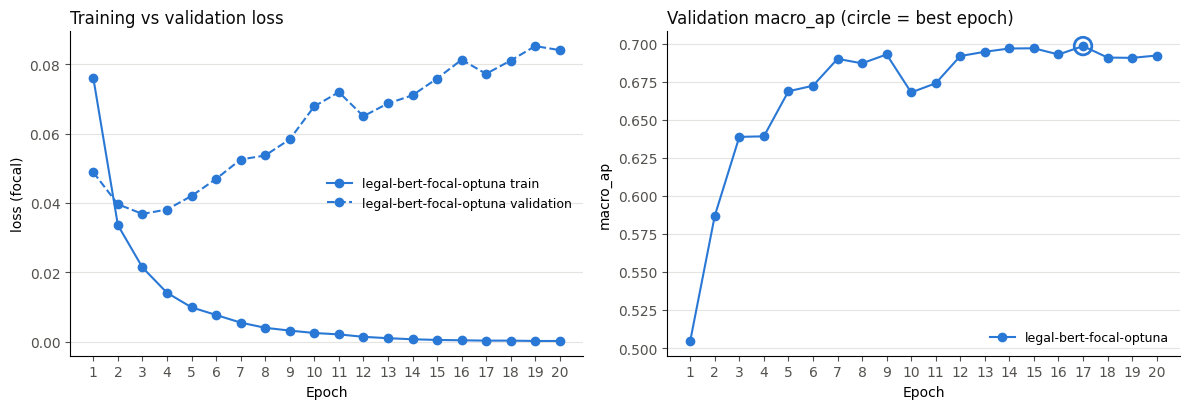

In [17]:
summaries, histories = {}, {}
for tag in RUNS:
    if os.path.exists(f"{RESULTS_DIR}/{tag}/summary.json"):
        with open(f"{RESULTS_DIR}/{tag}/summary.json") as f:
            summaries[tag] = json.load(f)
        histories[tag] = pd.read_csv(f"{RESULTS_DIR}/{tag}/epoch_history.csv")
assert summaries, "No finished runs found. Run section 6 first."

INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e5e4e0"
PALETTE = ["#2a78d6", "#eb6834", "#1a9a6c", "#8a5cd0", "#c9a227", "#d6457a", "#2f9fb0", "#7a7a7a", "#a0522d", "#3b5bdb"]
COLORS = {tag: PALETTE[i % len(PALETTE)] for i, tag in enumerate(RUNS)}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for tag, h in histories.items():
    axes[0].plot(h["epoch"], h["train_loss"], marker="o", color=COLORS[tag], label=f"{tag} train")
    axes[0].plot(h["epoch"], h["val_loss"], marker="o", linestyle="--", color=COLORS[tag], label=f"{tag} validation")
    axes[1].plot(h["epoch"], h[SELECT_METRIC], marker="o", color=COLORS[tag], label=tag)
    b = summaries[tag]["best_epoch"]
    axes[1].scatter([b], [h.loc[h["epoch"] == b, SELECT_METRIC].iloc[0]], s=160, facecolors="none",
                    edgecolors=COLORS[tag], linewidths=2, zorder=3)
axes[0].set_title("Training vs validation loss", loc="left", color=INK)
axes[0].set_ylabel("loss (focal)")
axes[1].set_title(f"Validation {SELECT_METRIC} (circle = best epoch)", loc="left", color=INK)
axes[1].set_ylabel(SELECT_METRIC)
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.set_xticks(sorted({e for h in histories.values() for e in h["epoch"]}))
    ax.grid(axis="y", color=GRID)
    ax.set_axisbelow(True)
    ax.legend(frameon=False, fontsize=9)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    ax.tick_params(colors=MUTED)
if MODE == "smoke":
    fig.suptitle("SMOKE RUN (CPU, tiny subset): checks the pipeline only, the numbers are not meaningful", color="#b3261e", fontsize=10)
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/loss_curves.png", dpi=150, bbox_inches="tight")
plt.show()

### Validation scores per epoch

In [18]:
table = pd.concat({tag: h.set_index("epoch") for tag, h in histories.items()}, names=["model", "epoch"])
table.round(4)

train_loss  val_loss  macro_ap  micro_ap  \
model                   epoch                                             
legal-bert-focal-optuna 1          0.0760    0.0488    0.5046    0.6249   
                        2          0.0336    0.0396    0.5869    0.6958   
                        3          0.0214    0.0368    0.6387    0.7420   
                        4          0.0141    0.0381    0.6391    0.7482   
                        5          0.0099    0.0420    0.6687    0.7544   
                        6          0.0077    0.0469    0.6723    0.7632   
                        7          0.0055    0.0525    0.6899    0.7739   
                        8          0.0040    0.0537    0.6870    0.7705   
                        9          0.0032    0.0584    0.6928    0.7803   
                        10         0.0025    0.0679    0.6679    0.7717   
                        11         0.0021    0.0720    0.6739    0.7776   
                        12         0.0014    0.0650    0.6918    0.7805   
                        13         0.0010    0.0687    0.6946    0.7816   
                        14         0.0007    0.0711    0.6968    0.7869   
                        15         0.0005    0.0759    0.6969    0.7927   
                        16         0.0004    0.0813    0.6928    0.7910   
                        17         0.0003    0.0773    0.6983    0.7905   
                        18         0.0003    0.0811    0.6908    0.7905   
                        19         0.0002    0.0853    0.6906    0.7926   
                        20         0.0002    0.0841    0.6921    0.7924   

                               micro_precision  micro_recall  micro_f1  \
model                   epoch                                            
legal-bert-focal-optuna 1               0.4498        0.6936    0.5457   
                        2               0.3915        0.8226    0.5305   
                        3               0.5078        0.8020    0.6219   
                        4               0.5515        0.7914    0.6500   
                        5               0.5951        0.7802    0.6752   
                        6               0.6189        0.7761    0.6886   
                        7               0.6398        0.7661    0.6972   
                        8               0.6534        0.7820    0.7119   
                        9               0.6869        0.7720    0.7270   
                        10              0.7025        0.7401    0.7208   
                        11              0.7209        0.7413    0.7310   
                        12              0.6989        0.7702    0.7328   
                        13              0.6970        0.7725    0.7328   
                        14              0.7030        0.7684    0.7342   
                        15              0.7295        0.7690    0.7487   
                        16              0.7345        0.7631    0.7486   
                        17              0.7153        0.7743    0.7436   
                        18              0.7222        0.7613    0.7413   
                        19              0.7381        0.7555    0.7467   
                        20              0.7332        0.7578    0.7453   

                               macro_f1  
model                   epoch            
legal-bert-focal-optuna 1        0.4380  
                        2        0.4817  
                        3        0.5575  
                        4        0.5781  
                        5        0.6065  
                        6        0.6212  
                        7        0.6174  
                        8        0.6358  
                        9        0.6547  
                        10       0.6214  
                        11       0.6348  
                        12       0.6579  
                        13       0.6589  
                        14       0.6517  
                        15       0.6672  
                        16       0.66

### Summary
Validation scores at the best epoch, chunk- and contract-level, with the training settings. The test columns stay empty until the test set is scored once (section 8). TF-IDF reference (`experimentation/TF-IDF/03_TF-IDF_model.ipynb`): test micro F1 0.591, macro F1 0.517 at 0.5.

In [19]:
TFIDF_TEST = {"micro_f1": 0.591, "macro_f1": 0.517}   # from experimentation/TF-IDF/03_TF-IDF_model.ipynb

best_tag = max(summaries, key=lambda t: summaries[t]["best_val"][WINNER_METRIC])   # the final model (validation only)
rows = []
for tag, s in summaries.items():
    test, cfg = s.get("test_at_best_epoch", {}), s.get("config", {})
    rows.append({"run": tag, "loss": " ".join(f"{k}{v}" if k != "type" else str(v) for k, v in s.get("loss", {}).items()
                                     if k in ("type", "gamma", "power", "cap")),
                 "learning_rate": cfg.get("learning_rate"), "epochs": cfg.get("num_epochs"), "best_epoch": s["best_epoch"],
                 "val_macro_ap": s["best_val"]["macro_ap"], "val_macro_f1": s["best_val"]["macro_f1"],
                 "val_micro_f1": s["best_val"]["micro_f1"], "val_contract_macro_f1": s.get("val_contract", {}).get("macro_f1"),
                 "test_macro_f1": test.get("macro_f1"), "test_micro_f1": test.get("micro_f1"),
                 "test_contract_macro_f1": s.get("test_contract", {}).get("macro_f1"), "train_minutes": s["train_minutes"]})
comparison = pd.DataFrame(rows).sort_values(f"val_{WINNER_METRIC}", ascending=False)
comparison = pd.concat([comparison, pd.DataFrame([{"run": "tf-idf baseline", "test_micro_f1": TFIDF_TEST["micro_f1"],
                                                    "test_macro_f1": TFIDF_TEST["macro_f1"]}])]).set_index("run")
comparison.to_csv(f"{RESULTS_DIR}/model_comparison.csv")

print(f"Final model: {best_tag}, best epoch {summaries[best_tag]['best_epoch']}, checkpoint: {summaries[best_tag]['checkpoint']}")
if MODE == "smoke":
    print("SMOKE RUN: these numbers only show the pipeline works. Re-run on a GPU for real results.")
comparison.T.round(3)

/tmp/ipykernel_548/1848491258.py:15: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  comparison = pd.concat([comparison, pd.DataFrame([{"run": "tf-idf baseline", "test_micro_f1": TFIDF_TEST["micro_f1"],


Final model: legal-bert-focal-optuna, best epoch 17, checkpoint: /content/drive/MyDrive/Accenture-1H-contract-review-challenge/models/training/15ep/legal-bert-focal-optuna/best


run,legal-bert-focal-optuna,tf-idf baseline
loss,focal gamma2 power0.5 cap10,NaN
learning_rate,0.000058,NaN
epochs,20.0,NaN
best_epoch,17.0,NaN
val_macro_ap,0.698336,NaN
val_macro_f1,0.662183,NaN
val_micro_f1,0.743633,NaN
val_contract_macro_f1,0.786899,NaN
test_macro_f1,NaN,0.517
test_micro_f1,NaN,0.591


### Per-category F1 on validation
Weakest categories first. Uses the validation probabilities saved with the run (recomputed from the checkpoint if missing).

In [20]:
FINAL = best_tag
COLS = ["input_ids", "attention_mask", "labels"]
val = prepare_splits(RUNS[FINAL]["model"])["validation"]
y_val = np.array(val["labels"]).astype(int)
path = f"{RESULTS_DIR}/{FINAL}/val_probs.npy"
if os.path.exists(path):
    val_probs = np.load(path)
else:
    model = AutoModelForSequenceClassification.from_pretrained(f"{MODELS_DIR}/{FINAL}/best")
    args = TrainingArguments(output_dir="/content/tmp_eval" if IN_COLAB else "../../models/tmp_eval",
                             per_device_eval_batch_size=CFG["per_device_batch_size"] * 2, bf16=USE_BF16, fp16=USE_FP16, report_to="none")
    trainer = Trainer(model=model, args=args, data_collator=DataCollatorWithPadding(tokenizers[RUNS[FINAL]["model"]]))
    val_probs = sigmoid(trainer.predict(val.select_columns(COLS)).predictions)
    np.save(path, val_probs)
    del trainer, model; gc.collect()
    if HAS_GPU:
        torch.cuda.empty_cache()

chunk, contract = multilabel_scores(y_val, val_probs), contract_level_scores(val["title"], y_val, val_probs)
print(f"{FINAL} (validation): chunk-level macro F1 {chunk['macro_f1']:.3f} | contract-level macro F1 {contract['macro_f1']:.3f} "
      f"(precision {contract['macro_precision']:.3f}, recall {contract['macro_recall']:.3f}, {contract['contracts']} contracts)")

has = y_val.sum(0) > 0
per_cat = pd.DataFrame({"val_positives": y_val.sum(0).astype(int),
                        "f1": [f1_score(y_val[:, j], val_probs[:, j] >= THRESHOLD, zero_division=0) if has[j] else np.nan
                               for j in range(len(CATEGORIES))]}, index=CATEGORIES).sort_values("f1")
f = per_cat["f1"].dropna()
for k in [5, 10]:
    print(f"Macro F1 without the {k} weakest categories = {f.iloc[k:].mean():.3f}")
per_cat.round(3)

legal-bert-focal-optuna (validation): chunk-level macro F1 0.662 | contract-level macro F1 0.787 (precision 0.785, recall 0.803, 61 contracts)
Macro F1 without the 5 weakest categories = 0.723
Macro F1 without the 10 weakest categories = 0.763


,val_positives,f1
Affiliate License-Licensor,3,0.000
Price Restrictions,8,0.200
No-Solicit Of Customers,8,0.267
Competitive Restriction Exception,14,0.286
Non-Disparagement,8,0.381
Volume Restriction,19,0.412
Source Code Escrow,9,0.429
Joint Ip Ownership,20,0.500
Affiliate License-Licensee,25,0.500
Post-Termination Services,70,0.525


## 8. Score the test set once
Once the team has agreed on the final model, set `FINAL_RUN = "legal-bert-focal-optuna"` in the settings cell and run this cell. It scores the saved checkpoint on the test set once (chunk- and contract-level) and writes `test_predictions.parquet`, the input for the risk classifier. Re-run the summary in section 7 to see the test scores next to the validation scores.

In [21]:
if FINAL_RUN is None:
    print(f"FINAL_RUN is not set. Final model: {best_tag}. "
          f'To score the test set once, set FINAL_RUN = "{best_tag}" in the settings cell and run this cell.')
else:
    assert FINAL_RUN == best_tag, f"FINAL_RUN ({FINAL_RUN}) is not the final model ({best_tag})"
    score_test_once(FINAL_RUN)

FINAL_RUN is not set. Final model: legal-bert-focal-optuna. To score the test set once, set FINAL_RUN = "legal-bert-focal-optuna" in the settings cell and run this cell.


## 9. Files saved
| File | In git | Contents |
|---|---|---|
| `results/training/15ep/<run name>/summary.json` | Yes | Best epoch, validation scores (chunk- and contract-level), loss and training settings; test scores once scored |
| `results/training/15ep/<run name>/epoch_history.csv` | Yes | Loss and validation scores per epoch |
| `results/training/15ep/<run name>/val_per_category.csv` | Yes | Validation AP per category |
| `results/training/15ep/<run name>/val_probs.npy` | Yes | Validation probabilities (2,069 chunks × 41 categories) |
| `results/training/15ep/<run name>/test_predictions.parquet` | Yes | `title`, `chunk_id`, 41 probabilities per test chunk (input for the risk classifier; written when the test set is scored) |
| `results/training/15ep/model_comparison.csv`, `loss_curves.png` | Yes | Summary table and loss/AP plot |
| `models/training/15ep/<run name>/best/` | No (~0.5 GB) | Best checkpoint, tokenizer, `training_info.json` |

On Colab these are under `MyDrive/Accenture-1H-contract-review-challenge/`. Smoke runs go to `models/training_smoke/'. Download them from Drive to commit them.

In [22]:
# Results are saved to Google Drive during the run; download them from there to commit them
if IN_COLAB and MODE == "full":
    print(f"Results are on Google Drive: {RESULTS_DIR}")
    print(f"Download the {RUNS_TO_RUN[0]}/ folder, model_comparison.csv and loss_curves.png, "
          f"and put them in results/training/{RUN_NAME}/ in the repo.")
else:
    print("Nothing to download here." if not IN_COLAB else "Smoke run: nothing worth downloading.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
# Release the GPU when the notebook has finished (full mode on Colab only)
if IN_COLAB and MODE == "full":
    from google.colab import runtime
    runtime.unassign()

## 10. Results and limitations
**Final model (validation set, 61 contracts):** chunk-level macro F1 **0.654–0.662** and contract-level macro F1 **0.787–0.796** across two seeds. Test-set results: *to be added once `FINAL_RUN` is scored.*

**How it compares (validation; details in `notebooks/experimentation/Transformer/`)**

| Model | Chunk-level macro F1 | Contract-level macro F1 |
|---|---|---|
| Legal-BERT, plain BCE (lr 2e-5) | 0.532 | – |
| Legal-BERT, class weights (lr 2e-5) | 0.623–0.626 | 0.771 |
| Focal loss + class weights (lr 2e-5) | 0.634 | 0.767 |
| Asymmetric loss (lr 2e-5) | 0.606 (0.636 at its best threshold) | 0.759 |
| Data variants (downsampling, Legal-BERT re-chunking) | 0.598–0.604* | 0.731–0.753 |
| ModernBERT (512 / 2,048-token chunks) | 0.584 / 0.532* | 0.700 / 0.618 |
| **Final: focal + class weights, tuned (lr 5.8e-5, 20 epochs)** | **0.654–0.662** | **0.787–0.796** |

\* Chunk-level scores of different chunkings are not directly comparable; use contract-level.

Class weighting gave the first large gain; the 8 weighting settings and the three losses then performed within noise of each other. Data variants and ModernBERT lowered contract-level F1 (legal-domain pretraining mattered more than context length). Tuning the learning rate and training length gave the only further clear gain (macro AP from about 0.65 to about 0.69).

**Limitations**
- Rare categories: Affiliate License-Licensor (3 validation examples) still scores 0, and categories with 14 or fewer examples swing widely between runs. Excluding the 5 weakest categories, chunk-level macro F1 would be about 0.72. More examples of these clauses are the most promising next step.
- All choices (including 8 Optuna trials) were made on the validation set, so validation scores are somewhat optimistic; the test set is scored once.
- Run-to-run noise is about ±0.01 (the same settings gave 0.624 and 0.634).
- The model is overconfident: validation loss rises after about epoch 3 while F1 and AP keep improving. Calibrate before using probabilities as confidence scores.
- Chunk labels count any overlap with a clause, so boundary chunks holding only a fragment add label noise.
- Price Restrictions has no test positives, so it is excluded from test averages.